# F26-13 Phase 5: analysis of results, error analysis and theoretical checks

Group F26-13 · AI2002 Artificial Intelligence, FAST-NUCES Lahore · Track A
*Confidence-Aware Self-Prompting for Robust Polyp Segmentation Under Image and Domain Shifts*

Everything here is read from the Phase 3 result files (`per_image.csv` and `detections.jsonl` for every run and dataset). Nothing is re-run on a GPU and no Phase 3 number changes; a Colab CPU runtime or a laptop is enough (about one minute).

| Section | What it shows | Report |
|---|---|---|
| 0 | Setup; check that the Phase 4 tables are reproduced exactly | §4 |
| 1 | The runs and the fallback rule F on both test sets | §1 |
| 2 | Where the gap to the oracle comes from (misses vs box quality) | §2 |
| 3 | Box-level signals: can YOLO confidence or SAM 2's score tell a true box from a false one? | §3, Figure 1 |
| 4 | Context: uncertain boxes with and without a confident box in the same image | §3, Figure 1 |
| 5 | Fallback rule F: error taxonomy and corrupted settings | §1, §2 |
| 6 | Second detector seed (43): the key results side by side | §3.4, Table 2 |

The seed-43 runs come from `notebooks/08_phase5_seed43_colab.ipynb` (Colab, T4).

Runs: **B** baseline (boxes ≥ 0.5), **T** threshold only (≥ 0.25), **C** CASP v1, **O** oracle (ground-truth boxes), **F_T / F_C** fallback rule (DL-44): boxes 0.25–0.5 used only in images with no box ≥ 0.5.

In [1]:
import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    if not os.path.exists("/content/proj"):
        subprocess.run(["git", "clone", "-q", "https://github.com/kashishfatima999/Confidence-Aware-Self-Prompting-for-Robust-Polyp-Segmentation.git", "/content/proj"], check=True)
    os.chdir("/content/proj")
    RUNS = "/content/drive/MyDrive/F26-13/runs_phase3"
    RUNS_S43 = "/content/drive/MyDrive/F26-13/runs_phase5_s43"
    YOLO_S43 = "/content/drive/MyDrive/F26-13/yolo/yolov8m_kvasir_s43/summary.json"
else:
    if os.path.basename(os.getcwd()) == "notebooks":
        os.chdir("..")
    RUNS = os.environ.get("F26_RUNS", "runs")
    RUNS_S43 = os.environ.get("F26_RUNS_S43", "runs/runs_phase5_s43")
    YOLO_S43 = os.environ.get("F26_YOLO_S43", "runs/yolov8m_kvasir_s43/summary.json")
print("runs folder:", RUNS, "| seed-43 runs:", RUNS_S43)

runs folder: runs | seed-43 runs: runs/runs_phase5_s43


## 0. The inputs are the Phase 3 files: Phase 4's tables are rebuilt and compared byte for byte

In [2]:
import filecmp, tempfile
tmp = tempfile.mkdtemp()
r = subprocess.run([sys.executable, "src/eval/compare.py", "--runs", RUNS, "--out", tmp], capture_output=True, text=True)
print(r.stdout.strip() or r.stderr[-1500:])
for f in ["metrics.csv", "comparison.csv"]:
    print(f, "identical to the committed Phase 4 table:", filecmp.cmp(f"{tmp}/{f}", f"docs/tables/phase4/{f}", shallow=False))

30 run summaries, 162 paired comparisons -> /tmp/tmpz0usidf4
metrics.csv identical to the committed Phase 4 table: True
comparison.csv identical to the committed Phase 4 table: True


In [3]:
r = subprocess.run([sys.executable, "src/eval/filter_analysis.py", "--runs", RUNS], capture_output=True, text=True)
print(r.stdout.strip() or r.stderr[-2000:])

39 run summaries, 120 paired comparisons, 1175 boxes -> docs/tables/phase5


## 1. All runs on both test sets (Dice with 95% bootstrap CI)

In [4]:
import pandas as pd, numpy as np
pd.set_option("display.width", 200)
m = pd.read_csv("docs/tables/phase5/fallback_metrics.csv")
cols = ["run", "dice", "dice_ci_low", "dice_ci_high", "iou", "pixel_precision", "pixel_recall", "missed", "box_precision", "box_recall", "box_f1"]
for ds in ["kvasir_test", "clinicdb"]:
    print(ds); display(m[m.dataset == ds][cols].set_index("run").round(3))

kvasir_test


,dice,dice_ci_low,dice_ci_high,iou,pixel_precision,pixel_recall,missed,box_precision,box_recall,box_f1
run,,,,,,,,,,
B,0.831,0.792,0.870,0.780,0.873,0.810,18,0.878,0.865,0.871
T,0.893,0.871,0.913,0.832,0.929,0.890,1,0.807,0.947,0.871
C,0.891,0.868,0.912,0.831,0.926,0.892,1,0.802,0.942,0.867
O,0.952,0.943,0.958,0.912,0.979,0.931,0,1.000,1.000,1.000
F_T,0.895,0.872,0.915,0.834,0.936,0.886,1,0.852,0.942,0.894
F_C,0.893,0.870,0.914,0.833,0.933,0.888,1,0.847,0.937,0.890


clinicdb


,dice,dice_ci_low,dice_ci_high,iou,pixel_precision,pixel_recall,missed,box_precision,box_recall,box_f1
run,,,,,,,,,,
B,0.677,0.648,0.710,0.628,0.712,0.671,144,0.890,0.686,0.774
T,0.760,0.736,0.785,0.698,0.800,0.764,75,0.820,0.780,0.799
C,0.757,0.734,0.783,0.695,0.795,0.765,75,0.815,0.776,0.795
O,0.945,0.942,0.948,0.899,0.966,0.928,0,1.000,1.000,1.000
F_T,0.756,0.731,0.782,0.695,0.805,0.753,75,0.859,0.763,0.808
F_C,0.756,0.731,0.782,0.694,0.802,0.754,75,0.857,0.762,0.807


In [5]:
p = pd.read_csv("docs/tables/phase5/fallback_comparison.csv")
p = p[(p.metric == "dice") & p.dataset.isin(["kvasir_test", "clinicdb"])].copy()
p["Dice difference [95% CI]"] = p.apply(lambda r: f"{r.mean_diff:+.3f} [{r.ci_low:+.3f}, {r.ci_high:+.3f}]", axis=1)
p["better / worse / tie"] = p.apply(lambda r: f"{r.better} / {r.worse} / {r.tie}", axis=1)
p.set_index(["dataset", "run", "reference"])[["Dice difference [95% CI]", "better / worse / tie"]]

Dice difference [95% CI] better / worse / tie
dataset     run reference                                              
kvasir_test F_T B          +0.064 [+0.035, +0.093]         17 / 0 / 183
                T          +0.002 [-0.003, +0.006]          4 / 5 / 191
                C          +0.003 [-0.003, +0.010]        16 / 15 / 169
            F_C B          +0.062 [+0.035, +0.091]         17 / 0 / 183
                T          -0.000 [-0.006, +0.005]         9 / 13 / 178
                C          +0.002 [-0.003, +0.007]         8 / 10 / 182
clinicdb    F_T B          +0.079 [+0.060, +0.098]         67 / 0 / 545
                T          -0.003 [-0.009, +0.002]        10 / 26 / 576
                C          -0.001 [-0.007, +0.005]        53 / 56 / 503
            F_C B          +0.078 [+0.060, +0.098]         67 / 0 / 545
                T          -0.004 [-0.010, +0.002]        33 / 51 / 528
                C          -0.002 [-0.008, +0.004]        28 / 33 / 551

## 2. Where the gap to the oracle comes from

An image with no prediction scores Dice 0 (DL-18), so mean Dice factorises exactly:
**mean Dice = P(image gets a mask) × E[Dice | it gets one]**. The first factor is the detector's recall at image level, the second is box quality plus SAM 2.

In [6]:
sys.path.insert(0, "src/eval")
from compare import load
from filter_analysis import fallback
rows = []
for ds in ["kvasir_test", "clinicdb"]:
    fr = {n: load(RUNS, r, ds) for n, r in [("B", "baseline"), ("T", "threshold_only"), ("C", "casp"), ("O", "oracle")]}
    fr["F_T"] = fallback(fr["B"], fr["T"])
    for n, df in fr.items():
        found = ~df.pred_empty.astype(bool)
        rows.append({"dataset": ds, "run": n, "P(mask)": found.mean(), "E[Dice | mask]": df.dice[found].mean(), "mean Dice": df.dice.mean()})
dec = pd.DataFrame(rows)
dec["check: product"] = dec["P(mask)"] * dec["E[Dice | mask]"]
display(dec.round(3))
for ds in ["kvasir_test", "clinicdb"]:
    t, o = dec[(dec.dataset == ds) & (dec.run == "T")].iloc[0], dec[(dec.dataset == ds) & (dec.run == "O")].iloc[0]
    miss = (o["P(mask)"] - t["P(mask)"]) * o["E[Dice | mask]"]
    qual = t["P(mask)"] * (o["E[Dice | mask]"] - t["E[Dice | mask]"])
    print(f"{ds}: O - T = {o['mean Dice'] - t['mean Dice']:.3f} = missed images {miss:.3f} + box quality {qual:.3f}")

,dataset,run,P(mask),E[Dice | mask],mean Dice,check: product
0,kvasir_test,B,0.910,0.913,0.831,0.831
1,kvasir_test,T,0.995,0.898,0.893,0.893
2,kvasir_test,C,0.995,0.896,0.891,0.891
3,kvasir_test,O,1.000,0.952,0.952,0.952
4,kvasir_test,F_T,0.995,0.899,0.895,0.895
5,clinicdb,B,0.765,0.886,0.677,0.677
6,clinicdb,T,0.877,0.866,0.760,0.760
7,clinicdb,C,0.877,0.863,0.757,0.757
8,clinicdb,O,1.000,0.945,0.945,0.945
9,clinicdb,F_T,0.877,0.862,0.756,0.756


kvasir_test: O - T = 0.059 = missed images 0.005 + box quality 0.054
clinicdb: O - T = 0.186 = missed images 0.116 + box quality 0.070


## 3. Box-level signals (T run: every kept box, labelled true / false positive against the oracle's ground-truth boxes)

In [7]:
sig = pd.read_csv("docs/tables/phase5/signal_auroc.csv")
sig["AUROC [95% CI]"] = sig.apply(lambda r: f"{r.auroc:.3f} [{r.ci_low:.3f}, {r.ci_high:.3f}]", axis=1)
sig.set_index(["dataset", "boxes", "signal"])[["n", "n_tp", "AUROC [95% CI]"]]

n  n_tp        AUROC [95% CI]
dataset     boxes                   signal                                                 
kvasir_test all kept boxes          YOLO confidence         243   196  0.861 [0.794, 0.916]
                                    SAM 2 score             243   196  0.685 [0.594, 0.768]
                                    confidence x SAM score  243   196  0.861 [0.794, 0.916]
                                    no box >= 0.5 in image  243   196  0.804 [0.734, 0.872]
            uncertain band 0.25-0.5 YOLO confidence          39    17  0.448 [0.254, 0.641]
                                    SAM 2 score              39    17  0.527 [0.340, 0.708]
                                    confidence x SAM score   39    17  0.471 [0.278, 0.666]
                                    no box >= 0.5 in image   39    17  0.766 [0.647, 0.875]
clinicdb    all kept boxes          YOLO confidence         615   504  0.820 [0.782, 0.855]
                                    SAM 2 score             615   504  0.656 [0.598, 0.709]
                                    confidence x SAM score  615   504  0.822 [0.785, 0.857]
                                    no box >= 0.5 in image  615   504  0.666 [0.620, 0.711]
            uncertain band 0.25-0.5 YOLO confidence         117    61  0.519 [0.418, 0.626]
                                    SAM 2 score             117    61  0.469 [0.366, 0.580]
                                    confidence x SAM score  117    61  0.512 [0.406, 0.615]
                                    no box >= 0.5 in image  117    61  0.678 [0.594, 0.762]

In [8]:
boxes = pd.read_csv("docs/tables/phase5/box_signals.csv", dtype={"image_id": str})
k = boxes[boxes.kept]
for ds, d in k.groupby("dataset"):
    tp = boxes[(boxes.dataset == ds) & boxes.tp]
    print(f"{ds}: median confidence of true boxes {tp.confidence.median():.3f}; share of true boxes at >= 0.5: {(tp.confidence >= 0.5).mean():.3f}, "
          f"0.25-0.5: {((tp.confidence >= 0.25) & (tp.confidence < 0.5)).mean():.3f}, < 0.25: {(tp.confidence < 0.25).mean():.3f}")
    print(f"   kept boxes: mean SAM score true {d[d.tp].sam_score.mean():.3f} vs false {d[~d.tp].sam_score.mean():.3f}; "
          f"false boxes with SAM score >= 0.8: {(d[~d.tp].sam_score >= 0.8).mean():.2f}; corr(confidence, SAM score) = {np.corrcoef(d.confidence, d.sam_score)[0, 1]:.2f}")

clinicdb: median confidence of true boxes 0.794; share of true boxes at >= 0.5: 0.773, 0.25-0.5: 0.106, < 0.25: 0.120
   kept boxes: mean SAM score true 0.925 vs false 0.901; false boxes with SAM score >= 0.8: 0.96; corr(confidence, SAM score) = 0.44
kvasir_test: median confidence of true boxes 0.873; share of true boxes at >= 0.5: 0.886, 0.25-0.5: 0.084, < 0.25: 0.030
   kept boxes: mean SAM score true 0.946 vs false 0.898; false boxes with SAM score >= 0.8: 0.91; corr(confidence, SAM score) = 0.36


## 4. Context: how often an uncertain box is a polyp

In [9]:
pd.read_csv("docs/tables/phase5/band_context.csv").round(3)

,dataset,image_has_box_ge_0.5,boxes,true_polyp,share_true,mean_sam_score_true,mean_sam_score_false
0,clinicdb,False,76,50,0.658,0.863,0.881
1,clinicdb,True,41,11,0.268,0.879,0.903
2,kvasir_test,False,25,16,0.640,0.914,0.926
3,kvasir_test,True,14,1,0.071,0.896,0.848


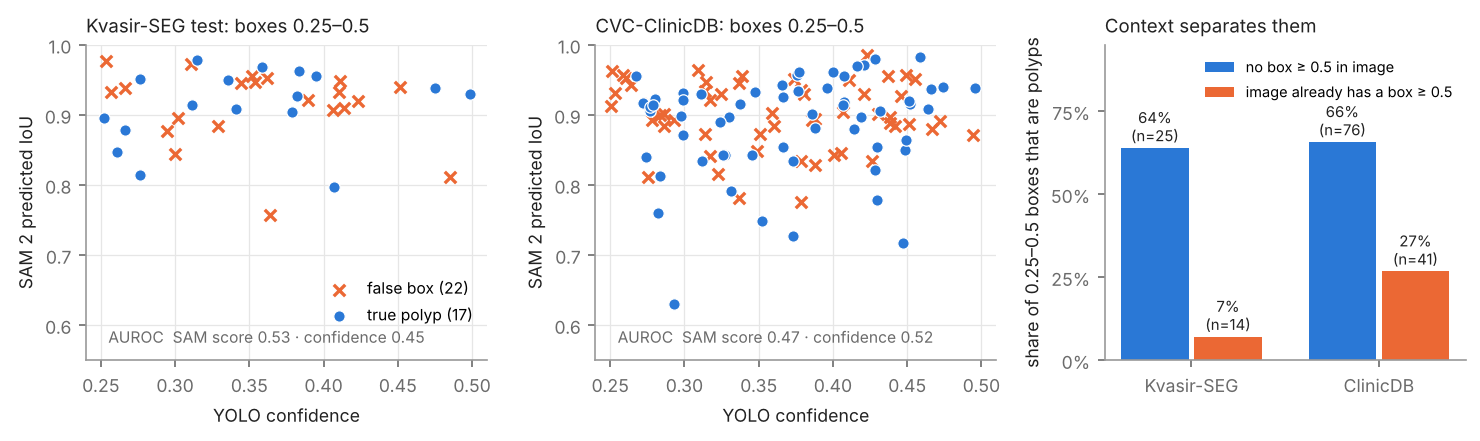

In [10]:
import matplotlib.pyplot as plt
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#222222", "#6b6b6b"
plt.rcParams.update({"font.size": 8.5, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#999999",
                     "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED, "figure.dpi": 150})
names = {"kvasir_test": "Kvasir-SEG test", "clinicdb": "CVC-ClinicDB"}
ctx = pd.read_csv("docs/tables/phase5/band_context.csv")
fig, axes = plt.subplots(1, 3, figsize=(10, 3.0), gridspec_kw={"width_ratios": [1, 1, 0.9]})
for ax, ds in zip(axes[:2], ["kvasir_test", "clinicdb"]):
    d = k[(k.dataset == ds) & k.band]
    s = sig[(sig.dataset == ds) & (sig.boxes.str.startswith("uncertain"))].set_index("signal")
    ax.scatter(d[~d.tp].confidence, d[~d.tp].sam_score, s=30, marker="x", color=ORANGE, linewidths=1.6, label=f"false box ({(~d.tp).sum()})")
    ax.scatter(d[d.tp].confidence, d[d.tp].sam_score, s=30, marker="o", color=BLUE, edgecolors="white", linewidths=0.6, label=f"true polyp ({d.tp.sum()})")
    ax.set_xlim(0.24, 0.51); ax.set_ylim(0.55, 1.0)
    ax.set_xlabel("YOLO confidence"); ax.set_ylabel("SAM 2 predicted IoU")
    ax.set_title(f"{names[ds]}: boxes 0.25–0.5", fontsize=9, color=INK, loc="left")
    ax.text(0.255, 0.575, f"AUROC  SAM score {s.loc['SAM 2 score','auroc']:.2f} · confidence {s.loc['YOLO confidence','auroc']:.2f}", fontsize=7.5, color=MUTED)
    ax.grid(color="#e6e6e6", linewidth=0.6); ax.set_axisbelow(True)
axes[0].legend(loc="lower right", frameon=False, fontsize=7.5, bbox_to_anchor=(1.0, 0.07))
ax = axes[2]
x = np.arange(2); w = 0.36
for i, (has, col, lab) in enumerate([(False, BLUE, "no box ≥ 0.5 in image"), (True, ORANGE, "image already has a box ≥ 0.5")]):
    vals = [ctx[(ctx.dataset == ds) & (ctx["image_has_box_ge_0.5"] == has)].share_true.iloc[0] for ds in ["kvasir_test", "clinicdb"]]
    ns = [ctx[(ctx.dataset == ds) & (ctx["image_has_box_ge_0.5"] == has)].boxes.iloc[0] for ds in ["kvasir_test", "clinicdb"]]
    bars = ax.bar(x + (i - 0.5) * (w + 0.03), vals, w, color=col, label=lab)
    for xb, v, n in zip(x + (i - 0.5) * (w + 0.03), vals, ns):
        ax.text(xb, v + 0.02, f"{v:.0%}\n(n={n})", ha="center", fontsize=7.2, color=INK)
ax.set_xticks(x, ["Kvasir-SEG", "ClinicDB"]); ax.set_ylim(0, 0.95); ax.set_yticks([0, 0.25, 0.5, 0.75])
ax.set_yticklabels(["0%", "25%", "50%", "75%"]); ax.set_ylabel("share of 0.25–0.5 boxes that are polyps")
ax.set_title("Context separates them", fontsize=9, color=INK, loc="left")
ax.legend(frameon=False, fontsize=7, loc="upper right")
fig.tight_layout()
fig.savefig("docs/figures/phase5_box_signals.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Fallback rule F: what changes in the error taxonomy, and the corrupted settings

In [11]:
err = pd.read_csv("docs/tables/phase5/fallback_errors.csv")
err[err.dataset.isin(["kvasir_test", "clinicdb"]) & err.run.isin(["B", "T", "C", "F_T", "O"])].set_index(["dataset", "run"])

images  good  extra_box  under_segmentation  over_segmentation  false_positive  missed
dataset     run                                                                                        
kvasir_test B       200   159         15                   6                  2               0      18
            T       200   160         29                   7                  3               0       1
            C       200   160         28                   7                  4               0       1
            O       200   199          0                   1                  0               0       0
            F_T     200   168         21                   7                  3               0       1
clinicdb    B       612   409         22                  26                  9               2     144
            T       612   426         59                  34                 16               2      75
            C       612   424         58                  34                 19               2      75
            O       612   610          0                   0                  2               0       0
            F_T     612   445         29                  42                 17               4      75

In [12]:
c = pd.read_csv("docs/tables/phase5/fallback_comparison.csv")
c = c[c.dataset.str.startswith("kvasir_corrupted") & (c.metric == "dice")].copy()
c["setting"] = c.dataset.str.replace("kvasir_corrupted_", "")
c["diff [95% CI]"] = c.apply(lambda r: f"{r.mean_diff:+.3f} [{r.ci_low:+.3f}, {r.ci_high:+.3f}]", axis=1)
c.pivot(index="setting", columns="reference", values="diff [95% CI]").rename(columns=lambda x: f"F_C − {x}")

reference,F_C − B,F_C − C
setting,,
blur_s1,"+0.036 [+0.015, +0.060]","+0.008 [+0.001, +0.018]"
blur_s2,"+0.044 [+0.021, +0.071]","+0.009 [+0.002, +0.016]"
blur_s3,"+0.084 [+0.051, +0.121]","+0.002 [-0.011, +0.014]"
brightness_contrast_s1,"+0.053 [+0.026, +0.083]","+0.007 [-0.004, +0.021]"
brightness_contrast_s2,"+0.055 [+0.027, +0.087]","+0.005 [-0.008, +0.019]"
brightness_contrast_s3,"+0.044 [+0.022, +0.070]","+0.004 [-0.007, +0.017]"
noise_s1,"+0.067 [+0.039, +0.099]","-0.007 [-0.021, +0.004]"
noise_s2,"+0.054 [+0.029, +0.084]","-0.019 [-0.036, -0.003]"
noise_s3,"+0.019 [+0.005, +0.039]","+0.000 [+0.000, +0.000]"


**Reading.** F keeps every polyp that T and C rescue (17 on Kvasir-SEG, 67 on ClinicDB, all over B) and matches their Dice (all CIs include zero on both test sets). It removes about half of the extra-box images and raises box precision and box F1. It is not free: on ClinicDB some 0.25–0.5 boxes next to a confident one cover a real second polyp or another part of a large one, and those are lost (box recall 0.780 → 0.763); and at noise severity 2 F_C is below C. The rule was fixed before these numbers were computed (DL-44) and uses no test-set tuning.

## 6. Second detector seed

YOLOv8-m retrained with seed 43 (same recipe) and B, T, C repeated on both test sets (`notebooks/08_phase5_seed43_colab.ipynb`). The oracle does not use the detector, so the seed-42 oracle labels the boxes of both seeds.

In [13]:
r = subprocess.run([sys.executable, "src/eval/seed_compare.py", "--s42", RUNS, "--s43", RUNS_S43,
                    "--yolo42", f"{RUNS}/yolo/yolov8m_kvasir_s42/summary.json", "--yolo43", YOLO_S43], capture_output=True, text=True)
print(r.stdout.strip() or r.stderr[-2000:])
sc = pd.read_csv("docs/tables/phase5/seed_comparison.csv")
for ds in ["kvasir_test", "clinicdb"]:
    print(ds)
    display(sc[sc.dataset == ds].pivot_table(index="quantity", columns="seed", values="value", sort=False).round(3))

80 rows -> docs/tables/phase5
kvasir_test


seed,42,43
quantity,,
Dice B,0.831,0.856
Dice T,0.893,0.885
Dice C,0.891,0.885
Dice F_T,0.895,0.890
box F1 T,0.871,0.852
extra-box images T,29.000,25.000
box F1 F_T,0.894,0.873
extra-box images F_T,21.000,19.000
missed images B,18.000,10.000


clinicdb


seed,42,43
quantity,,
Dice B,0.677,0.712
Dice T,0.760,0.783
Dice C,0.757,0.782
Dice F_T,0.756,0.782
box F1 T,0.799,0.814
extra-box images T,59.000,56.000
box F1 F_T,0.808,0.825
extra-box images F_T,29.000,24.000
missed images B,144.000,123.000


**Reading.** The gate's gain over B holds for both detectors but is smaller on Kvasir-SEG with seed 43, whose baseline misses fewer polyps (10 instead of 18). F matches T in Dice for both seeds, removes extra-box images and raises box F1 each time. SAM 2's score stays at chance level in the 0.25–0.5 band for both seeds, and image context stays the most informative signal on Kvasir-SEG.